# ENGE707 Kaggle Competition: Custom CNN Pipeline Development

## Cat and Dog Facial Feature Classification

This notebook completes **Task 3 Part A: Model Selection and Pipeline Development**.

It builds a custom convolutional neural network (CNN) from scratch and connects it to the preprocessing pipeline created in Notebook 2. The custom CNN will provide a baseline that can later be compared with a pretrained ResNet18 model.

This notebook will:

1. Load the saved training and validation splits.
2. Reuse the preprocessing configuration from Notebook 2.
3. Create the PyTorch datasets and data loaders.
4. Define and explain a custom CNN architecture.
5. Select and justify the loss function, optimiser, and initial hyperparameters.
6. Define reusable training, validation, and test-prediction functions.
7. Verify that the model accepts one image batch and returns eight output scores.
8. Save architecture and pipeline evidence for the report.

**The model is not trained in this notebook.** No epoch loop is called, no backpropagation is performed, and no model weights are updated. Full training and learning-curve analysis will be completed later for Task 4.

## 1. Import the Required Libraries

The libraries used here support file handling, reproducibility, image processing, plotting, and PyTorch model development.

No evaluation library is required because the model is not being trained or evaluated yet.

In [1]:
# Imports the libraries used to build and check the custom CNN
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

## 2. Set Reproducibility Values

Random seed `42` is applied to Python, NumPy, and PyTorch. It will also control training-data shuffling when training is performed later.

Reproducibility settings reduce avoidable differences between repeated experiments.

In [2]:
# Sets random seeds to make the experiment more repeatable
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)
print("PyTorch version:", torch.__version__)

Random seed: 42
PyTorch version: 2.11.0+cu128


## 3. Prepare Local or Kaggle File Access

The model will be trained later in a Kaggle Notebook because an NVIDIA GPU can train the CNN much faster than a CPU. This setup cell keeps the notebook usable both locally and on Kaggle.

On Kaggle, attach the competition dataset and a private input containing `train_split.csv`, `validation_split.csv`, and `preprocessing_config.json`. The code finds those files, creates links inside `/kaggle/working`, and never changes the read-only files under `/kaggle/input`.

In [3]:
# Finds the required inputs when running locally or on Kaggle
RUNNING_ON_KAGGLE = Path("/kaggle/input").exists()


def find_kaggle_input_file(filename):
    """Find one required file among the attached Kaggle inputs."""
    matches = sorted(Path("/kaggle/input").rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"Kaggle input file not found: {filename}. "
            "Attach the competition data and project-artifact input."
        )

    return matches[0]


def find_kaggle_image_directory(filename, split_name):
    """Find the train or test directory containing one known image."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    split_name = split_name.lower()

    matching_split = [
        path
        for path in matches
        if split_name in {part.lower() for part in path.parent.parts}
    ]

    if not matching_split:
        raise FileNotFoundError(
            f"Could not locate the Kaggle {split_name} image folder."
        )

    return matching_split[0].parent


if RUNNING_ON_KAGGLE:
    import shutil

    kaggle_project_root = Path("/kaggle/working")

    train_split_source = find_kaggle_input_file("train_split.csv")
    validation_split_source = find_kaggle_input_file(
        "validation_split.csv"
    )
    config_source = find_kaggle_input_file(
        "preprocessing_config.json"
    )
    submission_source = find_kaggle_input_file(
        "sample_submission.csv"
    )

    split_probe = pd.read_csv(
        train_split_source,
        dtype={"filename": "string"},
        nrows=1,
    )
    submission_probe = pd.read_csv(
        submission_source,
        dtype={"image_id": "string"},
        nrows=1,
    )

    train_probe_filename = split_probe.iloc[0]["filename"]
    test_probe_id = Path(str(submission_probe.iloc[0]["image_id"])).stem
    test_probe_filename = f"{int(test_probe_id):05d}.jpg"

    kaggle_train_images = find_kaggle_image_directory(
        train_probe_filename,
        "train",
    )
    kaggle_test_images = find_kaggle_image_directory(
        test_probe_filename,
        "test",
    )

    local_split_dir = kaggle_project_root / "splits"
    local_config_dir = (
        kaggle_project_root / "outputs" / "preprocessing"
    )
    local_data_dir = kaggle_project_root / "data"

    local_split_dir.mkdir(parents=True, exist_ok=True)
    local_config_dir.mkdir(parents=True, exist_ok=True)
    (local_data_dir / "train").mkdir(parents=True, exist_ok=True)
    (local_data_dir / "test").mkdir(parents=True, exist_ok=True)

    shutil.copy2(train_split_source, local_split_dir / "train_split.csv")
    shutil.copy2(
        validation_split_source,
        local_split_dir / "validation_split.csv",
    )
    shutil.copy2(
        config_source,
        local_config_dir / "preprocessing_config.json",
    )
    shutil.copy2(
        submission_source,
        local_data_dir / "sample_submission.csv",
    )

    train_link = local_data_dir / "train" / "train"
    test_link = local_data_dir / "test" / "test"

    if not train_link.exists():
        train_link.symlink_to(kaggle_train_images, target_is_directory=True)

    if not test_link.exists():
        test_link.symlink_to(kaggle_test_images, target_is_directory=True)

    print("Kaggle environment detected.")
    print("Kaggle training images:", kaggle_train_images)
    print("Kaggle test images:", kaggle_test_images)
else:
    print("Local project environment detected.")

Kaggle environment detected.
Kaggle training images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/train/train
Kaggle test images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/test/test


## 4. Locate the Project Files and Output Folders

The notebook may be opened from either the project folder or the `notebooks` folder. The code finds the project root automatically.

The original images and CSV files are read but never modified. New Task 3 evidence is written to `outputs/models/` and `outputs/figures/`. A future trained checkpoint will be stored locally in `models/`.

In [4]:
# Finds project files and prepares folders for model evidence
possible_project_roots = [
    Path.cwd(),
    Path.cwd().parent,
]

PROJECT_ROOT = next(
    (
        folder
        for folder in possible_project_roots
        if (folder / "splits" / "train_split.csv").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "The project folder could not be found. "
        "Check the notebook location and project structure."
    )

DATA_DIR = PROJECT_ROOT / "data"
TRAIN_IMAGE_DIR = DATA_DIR / "train" / "train"
TEST_IMAGE_DIR = DATA_DIR / "test" / "test"
SAMPLE_SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

TRAIN_SPLIT_PATH = PROJECT_ROOT / "splits" / "train_split.csv"
VALIDATION_SPLIT_PATH = (
    PROJECT_ROOT / "splits" / "validation_split.csv"
)
PREPROCESSING_CONFIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "preprocessing"
    / "preprocessing_config.json"
)

MODEL_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "models"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
CHECKPOINT_DIR = PROJECT_ROOT / "models"

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    TRAIN_IMAGE_DIR,
    TEST_IMAGE_DIR,
    SAMPLE_SUBMISSION_PATH,
    TRAIN_SPLIT_PATH,
    VALIDATION_SPLIT_PATH,
    PREPROCESSING_CONFIG_PATH,
]

missing_paths = [
    path for path in required_paths if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "The following required paths are missing:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

print("Project folder:", PROJECT_ROOT)
print("Model evidence folder:", MODEL_OUTPUT_DIR)
print("Local checkpoint folder:", CHECKPOINT_DIR)

Project folder: /kaggle/working
Model evidence folder: /kaggle/working/outputs/models
Local checkpoint folder: /kaggle/working/models


## 5. Load the Saved Configuration and Data Splits

Notebook 2 saved the preprocessing choices and exact membership of the training and validation subsets. Loading these files ensures that every model uses the same data and preprocessing.

Image IDs are loaded as text so leading zeros are preserved.

In [5]:
# Loads the saved preprocessing settings and original data splits
with open(PREPROCESSING_CONFIG_PATH) as configuration_file:
    preprocessing_config = json.load(configuration_file)

training_split = pd.read_csv(
    TRAIN_SPLIT_PATH,
    dtype={
        "image_id": "string",
        "class": "string",
        "filename": "string",
        "group_id": "string",
    },
)

validation_split = pd.read_csv(
    VALIDATION_SPLIT_PATH,
    dtype={
        "image_id": "string",
        "class": "string",
        "filename": "string",
        "group_id": "string",
    },
)

sample_submission = pd.read_csv(
    SAMPLE_SUBMISSION_PATH,
    dtype={"image_id": "string", "class": "string"},
)

def id_to_filename(image_id):
    """Convert an image ID into its five-digit JPG filename."""
    image_stem = Path(str(image_id)).stem
    return f"{int(image_stem):05d}.jpg"

sample_submission["filename"] = (
    sample_submission["image_id"].apply(id_to_filename)
)

IMAGE_SIZE = int(preprocessing_config["image_size"])
BATCH_SIZE = int(preprocessing_config["batch_size"])
CLASS_NAMES = list(preprocessing_config["class_names"])
CLASS_TO_INDEX = dict(preprocessing_config["class_to_index"])
INDEX_TO_CLASS = {
    int(index): class_name
    for class_name, index in CLASS_TO_INDEX.items()
}
NUMBER_OF_CLASSES = len(CLASS_NAMES)

print("Training images:", f"{len(training_split):,}")
print("Validation images:", f"{len(validation_split):,}")
print("Test images:", f"{len(sample_submission):,}")
print("Image size:", f"{IMAGE_SIZE} × {IMAGE_SIZE}")
print("Batch size:", BATCH_SIZE)
print("Classes:", NUMBER_OF_CLASSES)

Training images: 50,928
Validation images: 12,732
Test images: 29,443
Image size: 224 × 224
Batch size: 32
Classes: 8


## 6. Verify the Saved Split Before Model Development

The following checks confirm that Notebook 3 is using the intended data. The notebook stops if an image ID or exact-duplicate group appears in both development subsets.

In [6]:
# Checks that training and validation do not share identifiers or duplicate groups
shared_image_ids = (
    set(training_split["image_id"])
    & set(validation_split["image_id"])
)

shared_group_ids = (
    set(training_split["group_id"])
    & set(validation_split["group_id"])
)

expected_classes = set(CLASS_NAMES)
training_classes = set(training_split["class"])
validation_classes = set(validation_split["class"])

encoded_labels_are_valid = (
    training_split["label_index"].between(
        0, NUMBER_OF_CLASSES - 1
    ).all()
    and validation_split["label_index"].between(
        0, NUMBER_OF_CLASSES - 1
    ).all()
)

split_checks = pd.DataFrame(
    {
        "check": [
            "Training subset contains 50,928 images",
            "Validation subset contains 12,732 images",
            "Shared image IDs",
            "Shared duplicate groups",
            "All classes appear in training",
            "All classes appear in validation",
            "Encoded labels are between 0 and 7",
        ],
        "result": [
            len(training_split) == 50928,
            len(validation_split) == 12732,
            len(shared_image_ids),
            len(shared_group_ids),
            training_classes == expected_classes,
            validation_classes == expected_classes,
            encoded_labels_are_valid,
        ],
        "expected": [True, True, 0, 0, True, True, True],
    }
)

display(split_checks)

assert len(training_split) == 50928
assert len(validation_split) == 12732
assert len(shared_image_ids) == 0
assert len(shared_group_ids) == 0
assert training_classes == expected_classes
assert validation_classes == expected_classes
assert encoded_labels_are_valid

print("All saved-split checks passed.")

,check,result,expected
0,"Training subset contains 50,928 images",True,True
1,"Validation subset contains 12,732 images",True,True
2,Shared image IDs,0,0
3,Shared duplicate groups,0,0
4,All classes appear in training,True,True
5,All classes appear in validation,True,True
6,Encoded labels are between 0 and 7,True,True


All saved-split checks passed.


## 7. Select the Computing Device

PyTorch will use a CUDA GPU or Apple Metal Performance Shaders (MPS) when available. Otherwise, it will use the CPU.

The same code can therefore run in different environments without manually changing the device.

In [7]:
# Chooses a GPU when available or uses the CPU
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Selected device:", DEVICE)

Selected device: cuda


## 8. Recreate the Image Transformations

The transformations match Notebook 2. Training receives random augmentation, while validation and test images receive deterministic preprocessing only.

All images are converted to RGB when loaded, padded to a square, resized to `224 × 224`, converted to PyTorch tensors, and normalised using ImageNet values.

In [8]:
# Recreates the image preprocessing used in the previous notebook
class SquarePad:
    """Add equal padding around the shorter sides of an image."""

    def __init__(self, fill=(0, 0, 0)):
        self.fill = fill

    def __call__(self, image):
        width, height = image.size
        largest_side = max(width, height)

        horizontal_padding = largest_side - width
        vertical_padding = largest_side - height

        left_padding = horizontal_padding // 2
        right_padding = horizontal_padding - left_padding
        top_padding = vertical_padding // 2
        bottom_padding = vertical_padding - top_padding

        return ImageOps.expand(
            image,
            border=(
                left_padding,
                top_padding,
                right_padding,
                bottom_padding,
            ),
            fill=self.fill,
        )


IMAGENET_MEAN = preprocessing_config["normalisation_mean"]
IMAGENET_STD = preprocessing_config["normalisation_std"]
augmentation_config = preprocessing_config["training_augmentation"]

training_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.RandomHorizontalFlip(
            p=augmentation_config["horizontal_flip_probability"]
        ),
        transforms.RandomRotation(
            degrees=augmentation_config["maximum_rotation_degrees"],
            interpolation=InterpolationMode.BILINEAR,
            fill=(0, 0, 0),
        ),
        transforms.ColorJitter(
            brightness=augmentation_config["brightness_change"],
            contrast=augmentation_config["contrast_change"],
            saturation=augmentation_config["saturation_change"],
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

evaluation_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

print("Training transformation:")
print(training_transform)
print("\nValidation and test transformation:")
print(evaluation_transform)

Training transformation:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=bilinear, expand=False, fill=(0, 0, 0))
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation and test transformation:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 9. Create the PyTorch Dataset Class

The dataset class opens one image at a time and applies its assigned transformation in memory.

Training and validation items include a numerical label. Test items include only the processed image and its ID.

In [9]:
# Defines how to load an image and return its matching label
class FacialFeatureDataset(Dataset):
    """Load facial-feature images for PyTorch."""

    def __init__(
        self,
        dataframe,
        image_directory,
        transform,
        include_labels=True,
    ):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.transform = transform
        self.include_labels = include_labels

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_directory / row["filename"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            if self.transform is not None:
                image = self.transform(image)

        item = {
            "image": image,
            "image_id": row["image_id"],
        }

        if self.include_labels:
            item["label"] = int(row["label_index"])
            item["class_name"] = row["class"]

        return item

## 10. Create the Datasets and Data Loaders

The training loader is shuffled. Validation and test loaders keep a stable order.

`num_workers=0` is retained because it is reliable in Jupyter on macOS. Pinned memory is enabled only when CUDA is used.

In [10]:
# Creates dataset objects and batches for the saved subsets
training_dataset = FacialFeatureDataset(
    dataframe=training_split,
    image_directory=TRAIN_IMAGE_DIR,
    transform=training_transform,
    include_labels=True,
)

validation_dataset = FacialFeatureDataset(
    dataframe=validation_split,
    image_directory=TRAIN_IMAGE_DIR,
    transform=evaluation_transform,
    include_labels=True,
)

test_dataset = FacialFeatureDataset(
    dataframe=sample_submission,
    image_directory=TEST_IMAGE_DIR,
    transform=evaluation_transform,
    include_labels=False,
)

NUM_WORKERS = (
    4
    if RUNNING_ON_KAGGLE
    else int(preprocessing_config["num_workers"])
)
PIN_MEMORY = DEVICE.type == "cuda"

loader_performance_options = {}

if NUM_WORKERS > 0:
    loader_performance_options = {
        "persistent_workers": True,
        "prefetch_factor": 2,
    }

loader_generator = torch.Generator()
loader_generator.manual_seed(RANDOM_SEED)

training_loader = DataLoader(
    training_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=loader_generator,
    **loader_performance_options,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    **loader_performance_options,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    **loader_performance_options,
)

print("Training batches:", len(training_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))
print("Data-loader workers:", NUM_WORKERS)
print("Pinned memory:", PIN_MEMORY)

Training batches: 1592
Validation batches: 398
Test batches: 921
Data-loader workers: 4
Pinned memory: True


# Part A: Custom CNN Architecture and Pipeline

## 11. Architecture Selection

The custom CNN is a strong baseline built without pretrained weights. It contains four feature-extraction blocks. Each block uses two convolutions before max pooling so features can be refined before spatial information is reduced.

Each block contains:

1. A convolution that learns visual features.
2. Batch normalisation to support stable training.
3. ReLU activation to learn non-linear patterns.
4. A second convolution, batch normalisation, and ReLU.
5. Max pooling to reduce image width and height.

The channel depth increases from 32 to 256 while the spatial dimensions decrease. Adaptive average pooling then produces one value per final feature map. Dropout provides regularisation, and the linear output layer returns eight raw class scores called logits.

No Softmax layer is included in the model because cross-entropy loss applies the required probability calculation internally during training.

In [11]:
# Defines the custom CNN layers and how an image passes through them
class ConvolutionBlock(nn.Module):
    """Extract and refine features before reducing image size."""

    def __init__(self, input_channels, output_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                input_channels,
                output_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                output_channels,
                output_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

    def forward(self, images):
        return self.layers(images)


class CustomCNN(nn.Module):
    """Custom CNN for eight-class facial-feature classification."""

    def __init__(self, number_of_classes=8, dropout_rate=0.40):
        super().__init__()

        self.features = nn.Sequential(
            ConvolutionBlock(3, 32),
            ConvolutionBlock(32, 64),
            ConvolutionBlock(64, 128),
            ConvolutionBlock(128, 256),
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, number_of_classes),
        )

        self.apply(self._initialise_weights)

    @staticmethod
    def _initialise_weights(layer):
        if isinstance(layer, nn.Conv2d):
            nn.init.kaiming_normal_(
                layer.weight,
                mode="fan_out",
                nonlinearity="relu",
            )
        elif isinstance(layer, nn.BatchNorm2d):
            nn.init.ones_(layer.weight)
            nn.init.zeros_(layer.bias)
        elif isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, images):
        features = self.features(images)
        pooled_features = self.global_pool(features)
        logits = self.classifier(pooled_features)
        return logits

## 12. Create and Summarise the Model

The model is created with eight output scores and a dropout rate of 0.40. Kaiming initialisation is used for convolution layers because they are followed by ReLU activations.

The architecture summary records how the image dimensions and channel depth change through the network.

In [12]:
# Creates the CNN and counts its model parameters
DROPOUT_RATE = 0.40

model = CustomCNN(
    number_of_classes=NUMBER_OF_CLASSES,
    dropout_rate=DROPOUT_RATE,
).to(DEVICE)

total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

non_trainable_parameters = (
    total_parameters - trainable_parameters
)

parameter_summary = pd.DataFrame(
    {
        "parameter_type": [
            "Total parameters",
            "Trainable parameters",
            "Non-trainable parameters",
        ],
        "count": [
            total_parameters,
            trainable_parameters,
            non_trainable_parameters,
        ],
    }
)

architecture_summary = pd.DataFrame(
    {
        "stage": [
            "Input",
            "Convolution block 1",
            "Convolution block 2",
            "Convolution block 3",
            "Convolution block 4",
            "Adaptive average pooling",
            "Dropout",
            "Linear output",
        ],
        "main_operations": [
            "Normalised RGB image",
            "Two convolutions, batch normalisation, ReLU, max pooling",
            "Two convolutions, batch normalisation, ReLU, max pooling",
            "Two convolutions, batch normalisation, ReLU, max pooling",
            "Two convolutions, batch normalisation, ReLU, max pooling",
            "One value per final feature map",
            f"Drop {DROPOUT_RATE:.0%} of features during training",
            "Eight raw class scores",
        ],
        "output_shape_per_image": [
            "3 × 224 × 224",
            "32 × 112 × 112",
            "64 × 56 × 56",
            "128 × 28 × 28",
            "256 × 14 × 14",
            "256 × 1 × 1",
            "256",
            "8",
        ],
    }
)

print(model)
display(parameter_summary)
display(architecture_summary)

# Saves the table as a CSV file for later notebooks or report evidence
parameter_summary.to_csv(
    MODEL_OUTPUT_DIR / "custom_cnn_parameter_summary.csv",
    index=False,
)

# Saves the table as a CSV file for later notebooks or report evidence
architecture_summary.to_csv(
    MODEL_OUTPUT_DIR / "custom_cnn_architecture.csv",
    index=False,
)

CustomCNN(
  (features): Sequential(
    (0): ConvolutionBlock(
      (layers): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvolutionBlock(
      (layers): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): 

,parameter_type,count
0,Total parameters,1175272
1,Trainable parameters,1175272
2,Non-trainable parameters,0


,stage,main_operations,output_shape_per_image
0,Input,Normalised RGB image,3 × 224 × 224
1,Convolution block 1,"Two convolutions, batch normalisation, ReLU, m...",32 × 112 × 112
2,Convolution block 2,"Two convolutions, batch normalisation, ReLU, m...",64 × 56 × 56
3,Convolution block 3,"Two convolutions, batch normalisation, ReLU, m...",128 × 28 × 28
4,Convolution block 4,"Two convolutions, batch normalisation, ReLU, m...",256 × 14 × 14
5,Adaptive average pooling,One value per final feature map,256 × 1 × 1
6,Dropout,Drop 40% of features during training,256
7,Linear output,Eight raw class scores,8


## 13. Create an Architecture Diagram

The following vertical diagram provides report evidence of the complete custom CNN architecture. It shows the output produced by each main stage for one image.

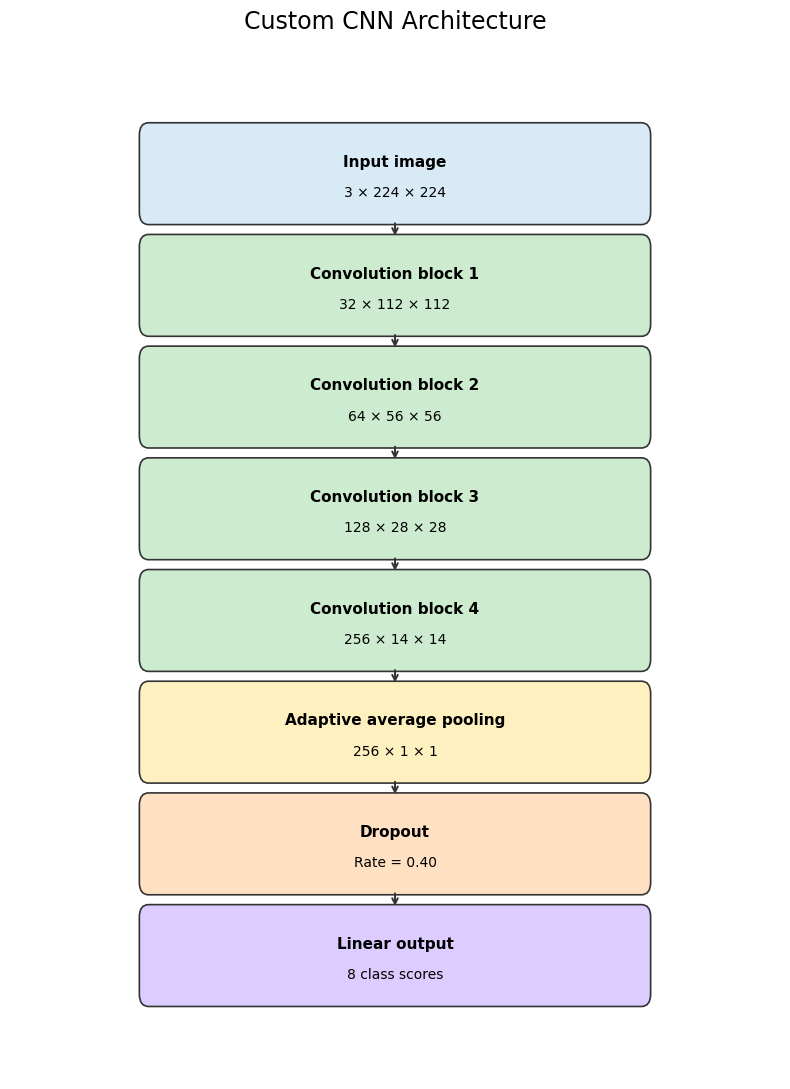

Figure saved to: /kaggle/working/outputs/figures/figure_11_custom_cnn_architecture.png


In [13]:
# Draws and saves the custom CNN architecture
diagram_stages = [
    ("Input image", "3 × 224 × 224", "#D9EAF7"),
    ("Convolution block 1", "32 × 112 × 112", "#CDECCF"),
    ("Convolution block 2", "64 × 56 × 56", "#CDECCF"),
    ("Convolution block 3", "128 × 28 × 28", "#CDECCF"),
    ("Convolution block 4", "256 × 14 × 14", "#CDECCF"),
    ("Adaptive average pooling", "256 × 1 × 1", "#FFF0BF"),
    ("Dropout", f"Rate = {DROPOUT_RATE:.2f}", "#FFE0C2"),
    ("Linear output", "8 class scores", "#DCCCFF"),
]

fig, ax = plt.subplots(figsize=(8, 11))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

box_x = 0.18
box_width = 0.64
box_height = 0.075
y_positions = np.linspace(0.88, 0.12, len(diagram_stages))

for stage_number, (stage_name, output_shape, colour) in enumerate(
    diagram_stages
):
    y_position = y_positions[stage_number]

    box = FancyBboxPatch(
        (box_x, y_position - box_height / 2),
        box_width,
        box_height,
        boxstyle="round,pad=0.012",
        facecolor=colour,
        edgecolor="#333333",
        linewidth=1.2,
    )

    ax.add_patch(box)
    ax.text(
        0.50,
        y_position + 0.012,
        stage_name,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
    )
    ax.text(
        0.50,
        y_position - 0.018,
        output_shape,
        ha="center",
        va="center",
        fontsize=10,
    )

    if stage_number < len(diagram_stages) - 1:
        next_y = y_positions[stage_number + 1]
        ax.annotate(
            "",
            xy=(0.50, next_y + box_height / 2 + 0.008),
            xytext=(0.50, y_position - box_height / 2 - 0.008),
            arrowprops={
                "arrowstyle": "->",
                "color": "#333333",
                "linewidth": 1.4,
            },
        )

ax.set_title(
    "Custom CNN Architecture",
    fontsize=17,
    pad=16,
)

architecture_figure_path = (
    FIGURE_DIR / "figure_11_custom_cnn_architecture.png"
)

plt.tight_layout()
# Saves the figure so it can be included in the report
plt.savefig(
    architecture_figure_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", architecture_figure_path)

## 14. Select the Loss Function, Optimiser, and Hyperparameters

The following values are justified starting settings. They cannot be described as optimal until training and validation experiments have been completed.

- **Cross-entropy loss** is suitable because each image belongs to one of eight classes and labels are integers from 0 to 7.
- **AdamW** provides adaptive parameter updates and applies weight decay correctly.
- **Learning rate 0.001** is a common starting value for AdamW when training a CNN from scratch.
- **Weight decay 0.0001** provides mild regularisation.
- **Batch size 32** balances memory use and stable gradient estimates.
- **Maximum 15 epochs** provides an initial training limit. Early stopping may finish sooner.
- **Patience 4** allows several epochs for validation performance to improve again before stopping.

The optimiser is created here, but `optimizer.step()` is not called anywhere in Part A.

In [14]:
# Sets the loss function optimiser and initial training settings
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
MAXIMUM_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 4
SCHEDULER_PATIENCE = 2
SCHEDULER_REDUCTION_FACTOR = 0.5

loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

learning_rate_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=SCHEDULER_REDUCTION_FACTOR,
        patience=SCHEDULER_PATIENCE,
    )
)

hyperparameter_summary = pd.DataFrame(
    {
        "hyperparameter": [
            "Input size",
            "Number of classes",
            "Batch size",
            "Maximum epochs",
            "Loss function",
            "Optimiser",
            "Learning rate",
            "Weight decay",
            "Dropout rate",
            "Early-stopping patience",
            "Scheduler patience",
            "Scheduler reduction factor",
        ],
        "value": [
            f"{IMAGE_SIZE} × {IMAGE_SIZE}",
            NUMBER_OF_CLASSES,
            BATCH_SIZE,
            MAXIMUM_EPOCHS,
            "CrossEntropyLoss",
            "AdamW",
            LEARNING_RATE,
            WEIGHT_DECAY,
            DROPOUT_RATE,
            EARLY_STOPPING_PATIENCE,
            SCHEDULER_PATIENCE,
            SCHEDULER_REDUCTION_FACTOR,
        ],
    }
)

display(hyperparameter_summary)

,hyperparameter,value
0,Input size,224 × 224
1,Number of classes,8
2,Batch size,32
3,Maximum epochs,15
4,Loss function,CrossEntropyLoss
5,Optimiser,AdamW
6,Learning rate,0.001
7,Weight decay,0.0001
8,Dropout rate,0.4
9,Early-stopping patience,4


## 15. Verify One Forward Pass

One validation batch is passed through the untrained model with gradients disabled. This confirms that the preprocessing and model are compatible.

This is **not training**. The model is placed in evaluation mode, no backward pass occurs, and the optimiser is not used. The resulting predictions are random and must not be reported as model performance.

In [15]:
# Passes one batch through the model without updating its weights
initial_parameter_snapshot = {
    name: parameter.detach().cpu().clone()
    for name, parameter in model.named_parameters()
}

validation_batch = next(iter(validation_loader))
batch_images = validation_batch["image"].to(DEVICE)
batch_labels = validation_batch["label"].to(DEVICE)

# Switches the model to evaluation behaviour for prediction
model.eval()

# Disables gradient tracking because this step does not train the model
with torch.no_grad():
    batch_logits = model(batch_images)
    compatibility_loss = loss_function(
        batch_logits,
        batch_labels,
    )
    untrained_predictions = batch_logits.argmax(dim=1)

print("Input batch shape:", tuple(batch_images.shape))
print("Output batch shape:", tuple(batch_logits.shape))
print("Loss output shape:", tuple(compatibility_loss.shape))
print("Finite compatibility loss:", bool(torch.isfinite(compatibility_loss)))
print("Predicted-index minimum:", int(untrained_predictions.min()))
print("Predicted-index maximum:", int(untrained_predictions.max()))

assert tuple(batch_images.shape) == (
    len(batch_images),
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
)
assert tuple(batch_logits.shape) == (
    len(batch_images),
    NUMBER_OF_CLASSES,
)
assert compatibility_loss.ndim == 0
assert torch.isfinite(compatibility_loss)
assert untrained_predictions.min() >= 0
assert untrained_predictions.max() < NUMBER_OF_CLASSES

print("The forward-pass compatibility check passed.")

Input batch shape: (32, 3, 224, 224)
Output batch shape: (32, 8)
Loss output shape: ()
Finite compatibility loss: True
Predicted-index minimum: 4
Predicted-index maximum: 4
The forward-pass compatibility check passed.


## 16. Define One Training Epoch

The function below describes how one future training epoch will work. It includes the forward pass, loss calculation, backpropagation, and weight update.

**The function is defined but not called in this notebook.**

In [16]:
# Defines how the model learns from one pass through the training batches
def train_one_epoch(
    model,
    data_loader,
    loss_function,
    optimizer,
    device,
):
    """Train a model for one epoch and return loss and accuracy."""
    # Switches the model to training behaviour for learning
    model.train()

    running_loss = 0.0
    correct_predictions = 0
    processed_images = 0

    for batch in data_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        # Clears gradients left over from the previous training batch
        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = loss_function(logits, labels)

        # Calculates how each weight contributed to the prediction error
        loss.backward()
        # Updates the model weights using the calculated gradients
        optimizer.step()

        predictions = logits.argmax(dim=1)
        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        correct_predictions += (predictions == labels).sum().item()
        processed_images += batch_size

    epoch_loss = running_loss / processed_images
    epoch_accuracy = correct_predictions / processed_images

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
    }

## 17. Define One Validation Epoch

Validation uses the labelled validation subset but does not update the model. Gradient calculation is disabled to reduce memory use and keep validation separate from training.

**The function is defined but not run across the validation set in this notebook.**

In [17]:
# Defines how to measure validation performance without updating weights
def validate_one_epoch(
    model,
    data_loader,
    loss_function,
    device,
):
    """Evaluate one validation epoch without updating weights."""
    # Switches the model to evaluation behaviour for prediction
    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    processed_images = 0

    # Disables gradient tracking because this step does not train the model
    with torch.no_grad():
        for batch in data_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)

            logits = model(images)
            loss = loss_function(logits, labels)
            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            correct_predictions += (predictions == labels).sum().item()
            processed_images += batch_size

    epoch_loss = running_loss / processed_images
    epoch_accuracy = correct_predictions / processed_images

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
    }

## 18. Define the Complete Future Training Controller

The controller connects the training and validation functions. When Task 4 begins, it can record learning history, reduce the learning rate when validation loss stops improving, save the best validation-accuracy checkpoint, and apply early stopping.

Defining the controller completes the planned training pipeline. **It is deliberately not called in Part A.**

In [18]:
# Defines the training loop and rules for saving the best model
def train_model(
    model,
    training_loader,
    validation_loader,
    loss_function,
    optimizer,
    scheduler,
    device,
    maximum_epochs,
    early_stopping_patience,
    checkpoint_path,
):
    """Run future training with checkpointing and early stopping."""
    history_rows = []
    best_validation_accuracy = -1.0
    epochs_without_improvement = 0

    for epoch_number in range(1, maximum_epochs + 1):
        current_learning_rate = optimizer.param_groups[0]["lr"]

        training_metrics = train_one_epoch(
            model,
            training_loader,
            loss_function,
            optimizer,
            device,
        )

        validation_metrics = validate_one_epoch(
            model,
            validation_loader,
            loss_function,
            device,
        )

        # Checks validation loss to decide whether the learning rate should change
        scheduler.step(validation_metrics["loss"])

        history_rows.append(
            {
                "epoch": epoch_number,
                "learning_rate": current_learning_rate,
                "training_loss": training_metrics["loss"],
                "training_accuracy": training_metrics["accuracy"],
                "validation_loss": validation_metrics["loss"],
                "validation_accuracy": validation_metrics["accuracy"],
            }
        )

        print(
            f"Epoch {epoch_number:02d}/{maximum_epochs} | "
            f"train loss {training_metrics['loss']:.4f} | "
            f"train accuracy {training_metrics['accuracy']:.4f} | "
            f"validation loss {validation_metrics['loss']:.4f} | "
            f"validation accuracy {validation_metrics['accuracy']:.4f}"
        )

        if validation_metrics["accuracy"] > best_validation_accuracy:
            best_validation_accuracy = validation_metrics["accuracy"]
            epochs_without_improvement = 0

            # Saves model weights and run information to the checkpoint file
            torch.save(
                {
                    "epoch": epoch_number,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "validation_accuracy": best_validation_accuracy,
                    "class_names": CLASS_NAMES,
                },
                checkpoint_path,
            )
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= early_stopping_patience:
            print("Early stopping was triggered.")
            break

    return pd.DataFrame(history_rows)


BEST_MODEL_PATH = CHECKPOINT_DIR / "custom_cnn_best.pth"

print("Training controller defined.")
print("Future checkpoint path:", BEST_MODEL_PATH)
print("The training controller has not been called.")

Training controller defined.
Future checkpoint path: /kaggle/working/models/custom_cnn_best.pth
The training controller has not been called.


## 19. Define the Kaggle Test-Prediction Function

The function below will later generate one prediction for every test image. It keeps the data-loader order, converts numerical predictions back into official class names, and returns a table matching the Kaggle format.

The function is not called because the model has not been trained. No submission is generated in Part A.

In [19]:
# Defines how to predict test labels in the required order
def predict_test_set(
    model,
    test_loader,
    index_to_class,
    device,
):
    """Return submission-ready predictions in test-loader order."""
    # Switches the model to evaluation behaviour for prediction
    model.eval()
    prediction_rows = []

    # Disables gradient tracking because this step does not train the model
    with torch.no_grad():
        for batch in test_loader:
            images = batch["image"].to(device)
            logits = model(images)
            predicted_indices = logits.argmax(dim=1).cpu().tolist()

            for image_id, predicted_index in zip(
                batch["image_id"],
                predicted_indices,
            ):
                prediction_rows.append(
                    {
                        "image_id": image_id,
                        "class": index_to_class[predicted_index],
                    }
                )

    return pd.DataFrame(prediction_rows)


test_order_matches = (
    test_dataset.dataframe["image_id"].astype("string").tolist()
    == sample_submission["image_id"].astype("string").tolist()
)

assert test_order_matches

print("Test prediction function defined.")
print("Test order matches sample_submission.csv:", test_order_matches)
print("No test predictions were generated.")

Test prediction function defined.
Test order matches sample_submission.csv: True
No test predictions were generated.


## 20. Save the Custom CNN Pipeline Configuration

The architecture and planned training settings are saved so Task 4 can use the same configuration.

The file clearly records that full training has not yet been performed.

In [20]:
# Saves the architecture and training configuration for later use
pipeline_configuration = {
    "model_name": "CustomCNN",
    "model_role": "Baseline model trained from scratch",
    "input_shape": [3, IMAGE_SIZE, IMAGE_SIZE],
    "number_of_classes": NUMBER_OF_CLASSES,
    "class_names": CLASS_NAMES,
    "convolution_blocks": 4,
    "convolutions_per_block": 2,
    "feature_channels": [32, 64, 128, 256],
    "activation": "ReLU",
    "pooling": "MaxPool2d and AdaptiveAvgPool2d",
    "dropout_rate": DROPOUT_RATE,
    "output_layer": f"Linear(256, {NUMBER_OF_CLASSES})",
    "output_values": "Raw logits; no Softmax inside the model",
    "weight_initialisation": "Kaiming for convolutions; Xavier for linear output",
    "loss_function": "CrossEntropyLoss",
    "optimiser": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "maximum_epochs": MAXIMUM_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_patience": SCHEDULER_PATIENCE,
    "scheduler_reduction_factor": SCHEDULER_REDUCTION_FACTOR,
    "random_seed": RANDOM_SEED,
    "training_performed": False,
}

pipeline_configuration_path = (
    MODEL_OUTPUT_DIR / "custom_cnn_pipeline_config.json"
)

with open(pipeline_configuration_path, "w") as configuration_file:
    json.dump(
        pipeline_configuration,
        configuration_file,
        indent=4,
    )

# Saves the table as a CSV file for later notebooks or report evidence
hyperparameter_summary.to_csv(
    MODEL_OUTPUT_DIR / "custom_cnn_hyperparameters.csv",
    index=False,
)

print("Pipeline configuration saved to:", pipeline_configuration_path)

Pipeline configuration saved to: /kaggle/working/outputs/models/custom_cnn_pipeline_config.json


## 21. Final Pipeline Checks

The final checks confirm that the saved split, preprocessing, architecture, loss function, and prediction structure connect correctly.

They also verify that the forward-pass check did not update the model parameters and that no complete training run or Kaggle submission occurred.

In [21]:
# Checks that the model pipeline is ready and the test pass changed no weights
parameters_unchanged = all(
    torch.equal(
        parameter.detach().cpu(),
        initial_parameter_snapshot[name],
    )
    for name, parameter in model.named_parameters()
)

PART_A_TRAINING_EXECUTED = False

pipeline_checks = pd.DataFrame(
    {
        "check": [
            "Training subset contains 50,928 images",
            "Validation subset contains 12,732 images",
            "Shared image IDs",
            "Shared duplicate groups",
            "Input batch has shape [32, 3, 224, 224]",
            "Model output has shape [32, 8]",
            "Cross-entropy returns one finite loss value",
            "All model parameters are trainable",
            "Forward check left parameters unchanged",
            "Test order matches sample submission",
            "Training controller was not called in Part A",
        ],
        "result": [
            len(training_dataset) == 50928,
            len(validation_dataset) == 12732,
            len(shared_image_ids),
            len(shared_group_ids),
            tuple(batch_images.shape),
            tuple(batch_logits.shape),
            compatibility_loss.ndim == 0
            and bool(torch.isfinite(compatibility_loss)),
            trainable_parameters == total_parameters,
            parameters_unchanged,
            test_order_matches,
            not PART_A_TRAINING_EXECUTED,
        ],
        "expected": [
            True,
            True,
            0,
            0,
            (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE),
            (BATCH_SIZE, NUMBER_OF_CLASSES),
            True,
            True,
            True,
            True,
            True,
        ],
    }
)

display(pipeline_checks)

assert parameters_unchanged
assert not PART_A_TRAINING_EXECUTED

# Saves the table as a CSV file for later notebooks or report evidence
pipeline_checks.to_csv(
    MODEL_OUTPUT_DIR / "custom_cnn_pipeline_checks.csv",
    index=False,
)

print("All Task 3 Part A pipeline checks passed.")
print("The custom CNN remains untrained.")

,check,result,expected
0,"Training subset contains 50,928 images",True,True
1,"Validation subset contains 12,732 images",True,True
2,Shared image IDs,0,0
3,Shared duplicate groups,0,0
4,"Input batch has shape [32, 3, 224, 224]","(32, 3, 224, 224)","(32, 3, 224, 224)"
5,"Model output has shape [32, 8]","(32, 8)","(32, 8)"
6,Cross-entropy returns one finite loss value,True,True
7,All model parameters are trainable,True,True
8,Forward check left parameters unchanged,True,True
9,Test order matches sample submission,True,True


All Task 3 Part A pipeline checks passed.
The custom CNN remains untrained.


# Task 3 Part A Conclusion

A complete custom CNN pipeline has been developed for the eight-class facial-feature classification problem. The model contains four feature-extraction blocks, adaptive average pooling, dropout, and an eight-output linear classifier.

The saved preprocessing pipeline connects correctly to the model: an input batch has shape `[32, 3, 224, 224]`, and the model returns output logits with shape `[32, 8]`. Cross-entropy loss, AdamW, an initial learning rate of 0.001, and regularisation settings have been defined as justified starting choices. Reusable functions for training, validation, early stopping, checkpointing, and ordered Kaggle prediction have also been implemented.

No model training, validation evaluation, learning-curve analysis, or Kaggle submission was performed. These activities remain for Task 4 and later assignment tasks.

# Part B: Task 4 - Training Strategy and Model Behaviour

Task 4 trains the custom CNN and monitors how it learns. It records training and validation loss and accuracy, saves the strongest checkpoint, produces learning curves, and provides evidence for discussing overfitting or underfitting.

The code is designed for a Kaggle Notebook with an NVIDIA GPU. Mixed-precision training, pinned memory, persistent data-loader workers, and non-blocking transfers are used on CUDA to improve speed. A 110-minute guard is included so the controller does not deliberately begin another epoch when its estimated completion would exceed the two-hour target.

**Training is disabled by default.** Runtime and accuracy cannot be guaranteed because they depend on the allocated Kaggle hardware and the real learning behaviour. Results must be interpreted only after a completed run.

## 22. Configure the Future Training Run

`RUN_TRAINING` is the safety switch for Task 4. Leave it as `False` while preparing or checking the notebook. Change it to `True` only inside a Kaggle GPU session when ready to train.

The time limit is set to 110 minutes, leaving approximately ten minutes before the requested two-hour boundary for notebook start-up, saving outputs, and small variations in epoch duration.

In [22]:
# Sets whether training runs and how long it is allowed to continue
RUN_TRAINING = True
TRAINING_TIME_LIMIT_MINUTES = 110

TRAINING_HISTORY_PATH = (
    MODEL_OUTPUT_DIR / "custom_cnn_training_history.csv"
)
TRAINING_SUMMARY_PATH = (
    MODEL_OUTPUT_DIR / "custom_cnn_training_summary.json"
)
LEARNING_CURVES_PATH = (
    FIGURE_DIR / "figure_12_custom_cnn_learning_curves.png"
)
GENERALISATION_STRATEGIES_PATH = (
    MODEL_OUTPUT_DIR / "custom_cnn_generalisation_strategies.csv"
)

print("Run training:", RUN_TRAINING)
print("Maximum epochs:", MAXIMUM_EPOCHS)
print("Training time guard:", TRAINING_TIME_LIMIT_MINUTES, "minutes")
print("Selected device:", DEVICE)

if RUN_TRAINING and RUNNING_ON_KAGGLE and DEVICE.type != "cuda":
    raise RuntimeError(
        "Kaggle training was enabled without a CUDA GPU. "
        "Select GPU under Notebook Settings > Accelerator."
    )

if not RUN_TRAINING:
    print("Training remains disabled. No weights will be updated.")

Run training: True
Maximum epochs: 15
Training time guard: 110 minutes
Selected device: cuda


## 23. Configure GPU-Efficient Training

Mixed precision uses 16-bit calculations where safe on a CUDA GPU. This normally reduces GPU memory use and can increase training speed. The loss scaler protects small gradients from becoming zero.

CUDA benchmarking is enabled because every processed image has the same `224 × 224` shape. CPU and Apple MPS execution remain supported, but mixed precision is enabled only for CUDA.

In [23]:
# Sets up faster GPU training when the required hardware is available
from contextlib import nullcontext
import time

USE_MIXED_PRECISION = DEVICE.type == "cuda"

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True


def mixed_precision_context(device, enabled):
    """Use CUDA automatic mixed precision when enabled."""
    if enabled and device.type == "cuda":
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )

    return nullcontext()


print("Mixed precision enabled:", USE_MIXED_PRECISION)
print("CUDA device count:", torch.cuda.device_count())

Mixed precision enabled: True
CUDA device count: 2


## 24. Define GPU-Optimised Training and Validation Epochs

The Task 4 epoch functions use non-blocking GPU transfers and mixed precision when CUDA is available. Training calculates gradients and updates weights. Validation disables gradients and never updates the model.

These functions are defined here but do nothing until the guarded training cell is enabled.

In [24]:
# Defines efficient batch handling and training and validation steps
def prepare_batch_for_device(batch, device):
    """Move one labelled batch to the selected device."""
    use_non_blocking = device.type == "cuda"

    images = batch["image"].to(
        device,
        non_blocking=use_non_blocking,
    )
    labels = batch["label"].to(
        device,
        non_blocking=use_non_blocking,
    )

    if device.type == "cuda":
        images = images.contiguous(
            memory_format=torch.channels_last
        )

    return images, labels


def train_one_epoch_task4(
    model,
    data_loader,
    loss_function,
    optimizer,
    gradient_scaler,
    device,
    use_mixed_precision,
):
    """Train for one epoch using optional CUDA mixed precision."""
    # Switches the model to training behaviour for learning
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    processed_images = 0

    for batch in data_loader:
        images, labels = prepare_batch_for_device(batch, device)
        # Clears gradients left over from the previous training batch
        optimizer.zero_grad(set_to_none=True)

        with mixed_precision_context(device, use_mixed_precision):
            logits = model(images)
            loss = loss_function(logits, labels)

        # Calculates how each weight contributed to the prediction error
        gradient_scaler.scale(loss).backward()
        # Applies the weight update safely when using mixed precision
        gradient_scaler.step(optimizer)
        gradient_scaler.update()

        predictions = logits.argmax(dim=1)
        current_batch_size = labels.size(0)

        running_loss += loss.item() * current_batch_size
        correct_predictions += (predictions == labels).sum().item()
        processed_images += current_batch_size

    return {
        "loss": running_loss / processed_images,
        "accuracy": correct_predictions / processed_images,
        "images": processed_images,
    }


def validate_one_epoch_task4(
    model,
    data_loader,
    loss_function,
    device,
    use_mixed_precision,
):
    """Measure validation loss and accuracy without updates."""
    # Switches the model to evaluation behaviour for prediction
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    processed_images = 0

    # Disables gradient tracking because this step does not train the model
    with torch.no_grad():
        for batch in data_loader:
            images, labels = prepare_batch_for_device(batch, device)

            with mixed_precision_context(device, use_mixed_precision):
                logits = model(images)
                loss = loss_function(logits, labels)

            predictions = logits.argmax(dim=1)
            current_batch_size = labels.size(0)

            running_loss += loss.item() * current_batch_size
            correct_predictions += (predictions == labels).sum().item()
            processed_images += current_batch_size

    return {
        "loss": running_loss / processed_images,
        "accuracy": correct_predictions / processed_images,
        "images": processed_images,
    }

## 25. Define Checkpointing, Scheduling, Early Stopping, and the Time Guard

The controller records every epoch immediately, reducing the risk of losing evidence if a Kaggle session is interrupted. The strongest validation-accuracy model is saved, validation loss controls the learning-rate scheduler, and early stopping ends training after four epochs without an accuracy improvement.

After each epoch, the controller uses that epoch's duration to estimate whether another epoch fits within the 110-minute training window.

In [25]:
# Defines checkpoint saving early stopping and the training time guard
def unwrap_model(model):
    """Return the underlying model when DataParallel is used."""
    return model.module if isinstance(model, nn.DataParallel) else model


def train_model_task4(
    model,
    training_loader,
    validation_loader,
    loss_function,
    optimizer,
    scheduler,
    gradient_scaler,
    device,
    maximum_epochs,
    early_stopping_patience,
    time_limit_minutes,
    checkpoint_path,
    history_path,
    use_mixed_precision,
):
    """Train with monitoring, recovery evidence, and time control."""
    history_rows = []
    best_validation_accuracy = -1.0
    epochs_without_improvement = 0
    stop_reason = "maximum_epochs"
    training_start_time = time.perf_counter()
    time_limit_seconds = time_limit_minutes * 60

    for epoch_number in range(1, maximum_epochs + 1):
        epoch_start_time = time.perf_counter()
        current_learning_rate = optimizer.param_groups[0]["lr"]

        training_metrics = train_one_epoch_task4(
            model,
            training_loader,
            loss_function,
            optimizer,
            gradient_scaler,
            device,
            use_mixed_precision,
        )
        validation_metrics = validate_one_epoch_task4(
            model,
            validation_loader,
            loss_function,
            device,
            use_mixed_precision,
        )

        # Checks validation loss to decide whether the learning rate should change
        scheduler.step(validation_metrics["loss"])
        epoch_seconds = time.perf_counter() - epoch_start_time
        total_seconds = time.perf_counter() - training_start_time
        accuracy_gap = (
            training_metrics["accuracy"]
            - validation_metrics["accuracy"]
        )

        history_rows.append(
            {
                "epoch": epoch_number,
                "learning_rate": current_learning_rate,
                "training_loss": training_metrics["loss"],
                "training_accuracy": training_metrics["accuracy"],
                "validation_loss": validation_metrics["loss"],
                "validation_accuracy": validation_metrics["accuracy"],
                "accuracy_gap": accuracy_gap,
                "epoch_seconds": epoch_seconds,
                "total_minutes": total_seconds / 60,
            }
        )

        history = pd.DataFrame(history_rows)
        # Saves the table as a CSV file for later notebooks or report evidence
        history.to_csv(history_path, index=False)

        validation_accuracy = validation_metrics["accuracy"]

        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            epochs_without_improvement = 0

            # Saves model weights and run information to the checkpoint file
            torch.save(
                {
                    "epoch": epoch_number,
                    "model_state_dict": unwrap_model(model).state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "validation_loss": validation_metrics["loss"],
                    "validation_accuracy": validation_accuracy,
                    "training_accuracy": training_metrics["accuracy"],
                    "class_names": CLASS_NAMES,
                },
                checkpoint_path,
            )
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch_number:02d}/{maximum_epochs} | "
            f"train loss {training_metrics['loss']:.4f} | "
            f"train accuracy {training_metrics['accuracy']:.4f} | "
            f"validation loss {validation_metrics['loss']:.4f} | "
            f"validation accuracy {validation_accuracy:.4f} | "
            f"{epoch_seconds / 60:.1f} minutes"
        )

        if epochs_without_improvement >= early_stopping_patience:
            stop_reason = "early_stopping"
            print("Early stopping was triggered.")
            break

        estimated_next_finish = total_seconds + epoch_seconds

        if estimated_next_finish >= time_limit_seconds:
            stop_reason = "time_guard"
            print(
                "The time guard stopped training before another epoch."
            )
            break

    training_information = {
        "epochs_completed": len(history_rows),
        "stop_reason": stop_reason,
        "total_training_minutes": (
            time.perf_counter() - training_start_time
        ) / 60,
    }

    return pd.DataFrame(history_rows), training_information

## 26. Record the Generalisation Strategies

The pipeline uses several complementary strategies to reduce overfitting and improve validation performance. Their effectiveness must later be judged from the real learning curves.

In [26]:
# Records the techniques used to support generalisation
generalisation_strategies = pd.DataFrame(
    {
        "strategy": [
            "Training augmentation",
            "Batch normalisation",
            "Dropout",
            "AdamW weight decay",
            "Learning-rate scheduling",
            "Early stopping",
            "Fixed validation split",
        ],
        "purpose": [
            "Expose the model to realistic visual variation",
            "Stabilise activations during learning",
            "Reduce reliance on individual pooled features",
            "Discourage unnecessarily large weights",
            "Use smaller updates when validation loss stops improving",
            "Stop after validation accuracy no longer improves",
            "Measure every epoch on the same unseen labelled images",
        ],
    }
)

display(generalisation_strategies)

# Saves the table as a CSV file for later notebooks or report evidence
generalisation_strategies.to_csv(
    GENERALISATION_STRATEGIES_PATH,
    index=False,
)

,strategy,purpose
0,Training augmentation,Expose the model to realistic visual variation
1,Batch normalisation,Stabilise activations during learning
2,Dropout,Reduce reliance on individual pooled features
3,AdamW weight decay,Discourage unnecessarily large weights
4,Learning-rate scheduling,Use smaller updates when validation loss stops...
5,Early stopping,Stop after validation accuracy no longer improves
6,Fixed validation split,Measure every epoch on the same unseen labelle...


## 27. Run or Skip Custom CNN Training

This is the only cell that starts the complete training run. A fresh model, optimiser, scheduler, and gradient scaler are created to ensure the experiment begins from the recorded random seed.

When two CUDA GPUs are allocated, `DataParallel` uses both. The best underlying model is still saved in a normal state dictionary.

In [27]:
# Runs training only when enabled and otherwise keeps the saved results
training_history = None
training_run_information = None

if RUN_TRAINING:
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    torch.manual_seed(RANDOM_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_SEED)

    training_model = CustomCNN(
        number_of_classes=NUMBER_OF_CLASSES,
        dropout_rate=DROPOUT_RATE,
    ).to(DEVICE)

    if DEVICE.type == "cuda":
        training_model = training_model.to(
            memory_format=torch.channels_last
        )

    if DEVICE.type == "cuda" and torch.cuda.device_count() > 1:
        training_model = nn.DataParallel(training_model)
        print("Using CUDA GPUs:", torch.cuda.device_count())

    task4_loss_function = nn.CrossEntropyLoss()
    task4_optimizer = torch.optim.AdamW(
        training_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
    task4_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        task4_optimizer,
        mode="min",
        factor=SCHEDULER_REDUCTION_FACTOR,
        patience=SCHEDULER_PATIENCE,
    )
    task4_gradient_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_MIXED_PRECISION,
    )

    training_history, training_run_information = train_model_task4(
        model=training_model,
        training_loader=training_loader,
        validation_loader=validation_loader,
        loss_function=task4_loss_function,
        optimizer=task4_optimizer,
        scheduler=task4_scheduler,
        gradient_scaler=task4_gradient_scaler,
        device=DEVICE,
        maximum_epochs=MAXIMUM_EPOCHS,
        early_stopping_patience=EARLY_STOPPING_PATIENCE,
        time_limit_minutes=TRAINING_TIME_LIMIT_MINUTES,
        checkpoint_path=BEST_MODEL_PATH,
        history_path=TRAINING_HISTORY_PATH,
        use_mixed_precision=USE_MIXED_PRECISION,
    )
else:
    print("Training was not started because RUN_TRAINING is False.")

Using CUDA GPUs: 2
Epoch 01/15 | train loss 0.8931 | train accuracy 0.6555 | validation loss 0.5466 | validation accuracy 0.8153 | 17.6 minutes
Epoch 02/15 | train loss 0.4111 | train accuracy 0.8540 | validation loss 0.3426 | validation accuracy 0.8827 | 7.7 minutes
Epoch 03/15 | train loss 0.2818 | train accuracy 0.9037 | validation loss 0.1733 | validation accuracy 0.9394 | 7.7 minutes
Epoch 04/15 | train loss 0.2217 | train accuracy 0.9237 | validation loss 0.1875 | validation accuracy 0.9333 | 7.7 minutes
Epoch 05/15 | train loss 0.1841 | train accuracy 0.9386 | validation loss 0.1561 | validation accuracy 0.9484 | 7.7 minutes
Epoch 06/15 | train loss 0.1592 | train accuracy 0.9472 | validation loss 0.1359 | validation accuracy 0.9538 | 7.7 minutes
Epoch 07/15 | train loss 0.1353 | train accuracy 0.9548 | validation loss 0.1046 | validation accuracy 0.9653 | 7.7 minutes
Epoch 08/15 | train loss 0.1204 | train accuracy 0.9604 | validation loss 0.0838 | validation accuracy 0.9716 | 

## 28. Load the History and Plot Learning Curves

The loss curves show whether optimisation is continuing to improve. The accuracy curves show the difference between performance on training images and unseen validation images.

No empty or invented graph is created before training results exist.

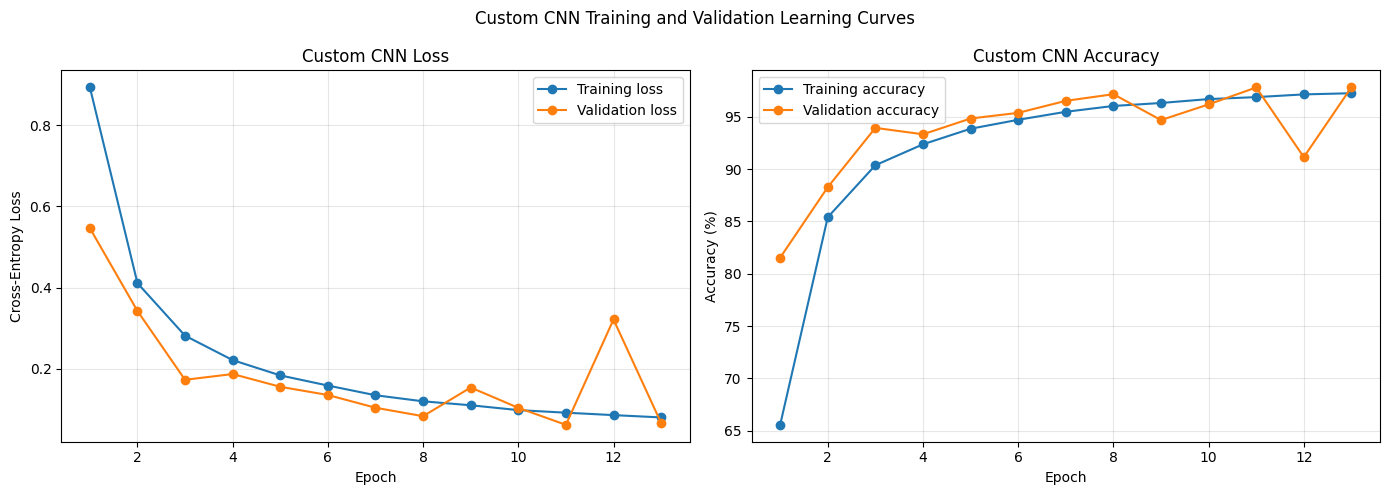

,epoch,learning_rate,training_loss,training_accuracy,validation_loss,validation_accuracy,accuracy_gap,epoch_seconds,total_minutes
0,1,0.001,0.8931,0.6555,0.5466,0.8153,-0.1598,1053.8948,17.5649
1,2,0.001,0.4111,0.8540,0.3426,0.8827,-0.0287,462.2763,25.2703
2,3,0.001,0.2818,0.9037,0.1733,0.9394,-0.0357,462.2554,32.9750
3,4,0.001,0.2217,0.9237,0.1875,0.9333,-0.0096,462.2080,40.6789
4,5,0.001,0.1841,0.9386,0.1561,0.9484,-0.0098,462.3133,48.3842
5,6,0.001,0.1592,0.9472,0.1359,0.9538,-0.0066,461.5899,56.0778
6,7,0.001,0.1353,0.9548,0.1046,0.9653,-0.0105,461.6210,63.7719
7,8,0.001,0.1204,0.9604,0.0838,0.9716,-0.0113,460.5806,71.4487
8,9,0.001,0.1107,0.9632,0.1544,0.9469,0.0163,460.4902,79.1240
9,10,0.001,0.0987,0.9670,0.1044,0.9619,0.0051,459.9965,86.7907


Learning curves saved to: /kaggle/working/outputs/figures/figure_12_custom_cnn_learning_curves.png


In [28]:
# Loads the saved training history and plots accuracy and loss
if TRAINING_HISTORY_PATH.exists():
    saved_training_history = pd.read_csv(TRAINING_HISTORY_PATH)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(
        saved_training_history["epoch"],
        saved_training_history["training_loss"],
        marker="o",
        label="Training loss",
    )
    axes[0].plot(
        saved_training_history["epoch"],
        saved_training_history["validation_loss"],
        marker="o",
        label="Validation loss",
    )
    axes[0].set_title("Custom CNN Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-Entropy Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(
        saved_training_history["epoch"],
        saved_training_history["training_accuracy"] * 100,
        marker="o",
        label="Training accuracy",
    )
    axes[1].plot(
        saved_training_history["epoch"],
        saved_training_history["validation_accuracy"] * 100,
        marker="o",
        label="Validation accuracy",
    )
    axes[1].set_title("Custom CNN Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    fig.suptitle("Custom CNN Training and Validation Learning Curves")
    plt.tight_layout()
    # Saves the figure so it can be included in the report
    plt.savefig(
        LEARNING_CURVES_PATH,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    display(saved_training_history.round(4))
    print("Learning curves saved to:", LEARNING_CURVES_PATH)
else:
    saved_training_history = None
    print("Learning curves are pending until training is completed.")

## 29. Reload and Verify the Best Checkpoint

Later evaluation should use the checkpoint with the highest validation accuracy, not automatically the final epoch. The best checkpoint is reloaded into a clean model and checked on all 12,732 validation images.

Detailed class metrics and the confusion matrix remain for Task 5.

In [29]:
# Reloads the best checkpoint and checks it on the validation images
best_model_validation = None
training_summary = None

if BEST_MODEL_PATH.exists() and TRAINING_HISTORY_PATH.exists():
    # Reads the saved checkpoint so training does not need to be repeated
    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False,
    )

    best_model = CustomCNN(
        number_of_classes=NUMBER_OF_CLASSES,
        dropout_rate=DROPOUT_RATE,
    ).to(DEVICE)
    # Copies the saved weights into the matching model architecture
    best_model.load_state_dict(checkpoint["model_state_dict"])

    if DEVICE.type == "cuda":
        best_model = best_model.to(
            memory_format=torch.channels_last
        )

    best_model_validation = validate_one_epoch_task4(
        best_model,
        validation_loader,
        nn.CrossEntropyLoss(),
        DEVICE,
        USE_MIXED_PRECISION,
    )

    saved_training_history = pd.read_csv(TRAINING_HISTORY_PATH)
    best_history_row = saved_training_history.loc[
        saved_training_history["validation_accuracy"].idxmax()
    ]

    stop_reason = (
        training_run_information["stop_reason"]
        if training_run_information is not None
        else "recorded_run"
    )

    training_summary = {
        "epochs_completed": int(len(saved_training_history)),
        "best_epoch": int(best_history_row["epoch"]),
        "best_validation_loss": float(checkpoint["validation_loss"]),
        "best_validation_accuracy": float(
            checkpoint["validation_accuracy"]
        ),
        "training_accuracy_at_best_epoch": float(
            best_history_row["training_accuracy"]
        ),
        "accuracy_gap_at_best_epoch": float(
            best_history_row["accuracy_gap"]
        ),
        "verified_validation_loss": float(
            best_model_validation["loss"]
        ),
        "verified_validation_accuracy": float(
            best_model_validation["accuracy"]
        ),
        "validation_images": int(
            best_model_validation["images"]
        ),
        "total_training_minutes": float(
            saved_training_history.iloc[-1]["total_minutes"]
        ),
        "stop_reason": stop_reason,
    }

    with open(TRAINING_SUMMARY_PATH, "w") as summary_file:
        json.dump(training_summary, summary_file, indent=4)

    display(pd.DataFrame([training_summary]).round(4))
    print("Training summary saved to:", TRAINING_SUMMARY_PATH)
else:
    print("Best-checkpoint verification is pending training.")

,epochs_completed,best_epoch,best_validation_loss,best_validation_accuracy,training_accuracy_at_best_epoch,accuracy_gap_at_best_epoch,verified_validation_loss,verified_validation_accuracy,validation_images,total_training_minutes,stop_reason
0,13,13,0.0671,0.9783,0.9726,-0.0058,0.0671,0.9783,12732,110.0007,time_guard


Training summary saved to: /kaggle/working/outputs/models/custom_cnn_training_summary.json


## 30. Prepare Evidence for Overfitting or Underfitting Analysis

The accuracy gap and the direction of validation loss provide evidence about generalisation. A large training advantage combined with worsening validation loss can indicate overfitting. Low and similar training and validation performance can indicate underfitting.

These values are displayed rather than converted into an absolute automatic diagnosis. The final report discussion must consider the complete curves and actual experiment results.

In [30]:
# Summarises the training and validation results for the report
if saved_training_history is not None:
    best_epoch_row = saved_training_history.loc[
        saved_training_history["validation_accuracy"].idxmax()
    ]
    final_epoch_row = saved_training_history.iloc[-1]

    behaviour_evidence = pd.DataFrame(
        {
            "measure": [
                "Best validation epoch",
                "Training accuracy at best epoch",
                "Validation accuracy at best epoch",
                "Accuracy gap at best epoch",
                "Lowest validation loss",
                "Final training accuracy",
                "Final validation accuracy",
                "Final validation loss",
            ],
            "value": [
                int(best_epoch_row["epoch"]),
                best_epoch_row["training_accuracy"],
                best_epoch_row["validation_accuracy"],
                best_epoch_row["accuracy_gap"],
                saved_training_history["validation_loss"].min(),
                final_epoch_row["training_accuracy"],
                final_epoch_row["validation_accuracy"],
                final_epoch_row["validation_loss"],
            ],
        }
    )

    display(behaviour_evidence.round(4))
else:
    behaviour_evidence = None
    print("Model-behaviour evidence is pending training.")

,measure,value
0,Best validation epoch,13.0000
1,Training accuracy at best epoch,0.9726
2,Validation accuracy at best epoch,0.9783
3,Accuracy gap at best epoch,-0.0058
4,Lowest validation loss,0.0625
5,Final training accuracy,0.9726
6,Final validation accuracy,0.9783
7,Final validation loss,0.0671


## 31. Task 4 Status and Final Checks

This section verifies that the training history, checkpoint, learning curves, validation coverage, and recorded values are complete and valid. If the training artifacts are absent, it reports that training is still pending.

The Kaggle test loader is never used by the training controller.

In [ ]:
# Checks that training records checkpoints and evidence were saved
required_history_columns = {
    "epoch",
    "learning_rate",
    "training_loss",
    "training_accuracy",
    "validation_loss",
    "validation_accuracy",
    "accuracy_gap",
    "epoch_seconds",
    "total_minutes",
}

if saved_training_history is None:
    TASK_4_STATUS = "Pending - training code prepared but not executed"
    print("Task 4 status:", TASK_4_STATUS)
else:
    loss_values_are_finite = np.isfinite(
        saved_training_history[
            ["training_loss", "validation_loss"]
        ].to_numpy()
    ).all()
    accuracy_values_are_valid = (
        saved_training_history[
            ["training_accuracy", "validation_accuracy"]
        ]
        .apply(lambda column: column.between(0, 1).all())
        .all()
    )

    task4_checks = pd.DataFrame(
        {
            "check": [
                "At least one epoch completed",
                "All required history columns exist",
                "All loss values are finite",
                "All accuracy values are between 0 and 1",
                "Best checkpoint exists",
                "Learning-curves figure exists",
                "Training summary exists",
                "Best model checked on all validation images",
                "Training completed within the two-hour limit",
            ],
            "result": [
                len(saved_training_history) >= 1,
                required_history_columns.issubset(
                    saved_training_history.columns
                ),
                loss_values_are_finite,
                accuracy_values_are_valid,
                BEST_MODEL_PATH.exists(),
                LEARNING_CURVES_PATH.exists(),
                TRAINING_SUMMARY_PATH.exists(),
                best_model_validation is not None
                and best_model_validation["images"]
                == len(validation_dataset),
                saved_training_history.iloc[-1]["total_minutes"]
                <= 120,
            ],
            "expected": [True] * 9,
        }
    )

    display(task4_checks)
    assert task4_checks["result"].all()

    TASK_4_STATUS = "Completed and verified"
    print("Task 4 status:", TASK_4_STATUS)

# Task 4 Conclusion

The custom CNN completed 13 epochs before the time guard stopped the run at approximately 110 minutes. The best checkpoint was recorded at epoch 13, with a validation accuracy of 97.83% and validation loss of 0.0671. Training accuracy at that epoch was 97.26%, so validation accuracy was approximately 0.58 percentage points higher.

Validation performance fluctuated during training, particularly at epochs 9 and 12, but recovered afterward. Best-model checkpointing prevented these temporary decreases from replacing the strongest model. The small final training-validation gap provides no evidence of persistent overfitting, although this result will be examined further through class-level evaluation and misclassification analysis in Notebook 5.

In [32]:
# Packages the saved custom CNN results for download
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

working_directory = Path("/kaggle/working")

result_files = [
    working_directory / "models" / "custom_cnn_best.pth",
    working_directory / "outputs" / "models"
    / "custom_cnn_training_history.csv",
    working_directory / "outputs" / "models"
    / "custom_cnn_training_summary.json",
    working_directory / "outputs" / "figures"
    / "figure_12_custom_cnn_learning_curves.png",
]

for result_file in result_files:
    if not result_file.exists():
        raise FileNotFoundError(f"Missing result: {result_file}")

archive_path = (
    working_directory / "custom_cnn_baseline_results.zip"
)

with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
    for result_file in result_files:
        archive.write(
            result_file,
            arcname=result_file.relative_to(working_directory),
        )

print("Saved:", archive_path)
print("Archive size:", f"{archive_path.stat().st_size / 1_000_000:.1f} MB")

display(FileLink(archive_path.name))

Saved: /kaggle/working/custom_cnn_baseline_results.zip
Archive size: 13.3 MB


/kaggle/working/custom_cnn_baseline_results.zip